# Repaso: regresión lineal y los conceptos del entrenamiento

La regresión lineal es el modelo más sencillo que aprende a partir de datos. En este notebook lo programamos **desde cero con NumPy**: escribimos nosotros mismos la predicción, la pérdida, las derivadas y la actualización de los parámetros. No usamos ninguna librería de aprendizaje profundo ni cálculo automático de derivadas.

Con este ejemplo repasamos los conceptos que aparecen en cualquier entrenamiento:

- **Modelo** y **parámetros**
- **Predicción** (*forward*)
- **Pérdida** (*loss*) y **función de costo**
- **Gradiente** y **derivadas**
- **Paso de optimización** (*step*) y **tasa de aprendizaje** (*learning rate*)
- **Iteración**, **época** (*epoch*), **batch** (*batch*) y **minibatch** (*mini-batch*)

No necesitas saber cálculo avanzado: solo derivadas de polinomios sencillos, y cada una se muestra con fórmula y con código que puedes comprobar.

### Notación: de la presentación al código

Este notebook acompaña a la presentación interactiva (`linear_regression.html`). En la presentación los símbolos son matemáticos; en el código usamos nombres más cortos. Esta es la equivalencia:

| En la presentación | En el código | Qué es |
|---|---|---|
| $w_1$ | `w` | pendiente |
| $w_0$ | `b` | sesgo (*bias*) |
| $\hat{y}$ | `y_hat` | predicción |
| $\nabla_{w_1}L$, $\nabla_{w_0}L$ | `dw`, `db` | derivadas de la pérdida |
| $\eta$ | `lr` | tasa de aprendizaje |
| $m$ | `batch_size` | tamaño del batch |
| $N$ | `N` | número de muestras |

## Etapa 1: El problema y los datos

Queremos predecir un valor $y$ a partir de un valor $x$. Generamos datos a partir de una recta conocida, $y = 2x + 1$, y le sumamos un poco de ruido.

- **Entrada** (*feature*): $x$.
- **Etiqueta** (*target*): $y$, el valor correcto que queremos aprender.
- **Muestra** o **ejemplo**: un par $(x, y)$.

Como conocemos la respuesta correcta ($w = 2$, $b = 1$), podremos comprobar si el entrenamiento la encuentra.

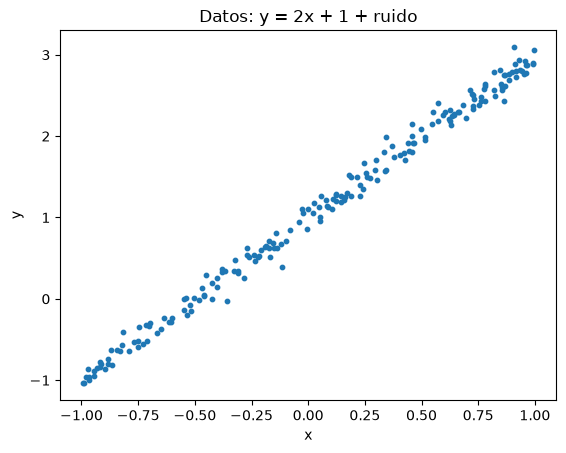

In [1]:
import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(0)     # generador de números aleatorios con semilla fija

N = 200                            # número de muestras
w_real, b_real = 2.0, 1.0          # la recta "verdadera"

x = rng.uniform(-1, 1, size=N)                    # entradas en [-1, 1]
y = w_real * x + b_real + 0.1 * rng.normal(size=N)  # etiquetas con ruido

plt.scatter(x, y, s=10)
plt.title('Datos: y = 2x + 1 + ruido')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

## Etapa 2: El modelo

El modelo de regresión lineal es una recta:

$$
\hat{y} = w\,x + b
$$

- $\hat{y}$ (se lee "y gorrito") es la **predicción** del modelo.
- $w$ es la **pendiente** y $b$ el **sesgo** (*bias*). Son los **parámetros**: los números que el entrenamiento va a ajustar.

Al empezar, no sabemos los valores correctos, así que los elegimos al azar. Predecir con el modelo se llama **forward** (paso hacia adelante): tomamos las entradas, aplicamos los parámetros y obtenemos las predicciones.

Parámetros iniciales -> w: -1.0955   b: 0.3625
Primeras 5 predicciones: [ 0.062  0.867  1.368  1.422 -0.324]
Primeras 5 etiquetas:    [ 1.489  0.032 -0.777 -1.     2.192]


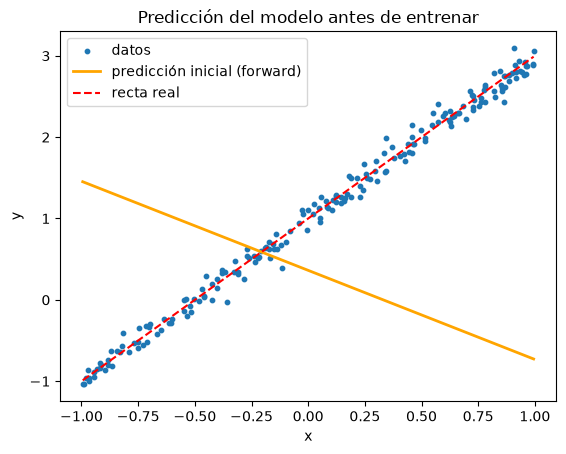

In [2]:
def predict(x, w, b):
    return w * x + b

w = rng.normal()
b = rng.normal()
print(f'Parámetros iniciales -> w: {w:.4f}   b: {b:.4f}')

y_hat = predict(x, w, b)          # forward
print('Primeras 5 predicciones:', np.round(y_hat[:5], 3))
print('Primeras 5 etiquetas:   ', np.round(y[:5], 3))

# Predicción inicial (naranja) frente a los datos y a la recta real (roja punteada)
x_line = np.linspace(x.min(), x.max(), 100)
plt.scatter(x, y, s=10, label='datos')
plt.plot(x_line, predict(x_line, w, b), color='orange', linewidth=2, label='predicción inicial (forward)')
plt.plot(x_line, w_real * x_line + b_real, color='red', linestyle='--', label='recta real')
plt.title('Predicción del modelo antes de entrenar')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

La recta naranja es la predicción del modelo con los parámetros iniciales (elegidos al azar): está lejos de los datos y de la recta real (roja punteada). Esto es normal, el modelo todavía no ha aprendido nada; solo acabamos de hacer un **forward pass** con parámetros al azar.


## Etapa 3: La pérdida (*loss*)

Necesitamos medir qué tan mal predice el modelo. Esa medida es la **pérdida** o **función de costo**. Usamos el **error cuadrático medio** (MSE):

$$
L(w, b) = \frac{1}{N}\sum_{i=1}^{N} \left(\hat{y}_i - y_i\right)^2 = \frac{1}{N}\sum_{i=1}^{N} \left(w\,x_i + b - y_i\right)^2
$$

Cada término es el error de una muestra, elevado al cuadrado para que los errores positivos y negativos no se cancelen. Un valor cercano a cero significa predicciones cercanas a las etiquetas.

La pérdida depende de $w$ y $b$. **Entrenar significa encontrar los valores de $w$ y $b$ que hacen mínima la pérdida.**

In [3]:
def compute_loss(y_hat, y):
    return np.mean((y_hat - y) ** 2)

print(f'Pérdida con los parámetros iniciales: {compute_loss(y_hat, y):.4f}')


Pérdida con los parámetros iniciales: 4.2264


<p align="center">
  <img src="imagenes/05_perdida_en_funcion_de_w.png" alt="Pérdida en función de w con b fijo" width="440">
  &nbsp;&nbsp;
  <img src="imagenes/06_superficie_perdida.png" alt="Superficie de pérdida L(w, b) con el punto real y el inicial" width="440">
</p>

La gráfica de la derecha es la versión completa de la de la izquierda: en la izquierda solo movemos $w$ con $b$ fijo; en la derecha movemos los dos a la vez. Cada color es el valor de la pérdida para una combinación $(w, b)$: los tonos morados/oscuros son pérdidas bajas (el fondo de un "tazón"), los tonos amarillos son pérdidas altas. La estrella roja marca el punto real $(w, b) = (2, 1)$, donde la pérdida es mínima; el punto blanco es donde arranca el entrenamiento.

**Entrenar es moverse por esta superficie, desde el punto blanco hasta el fondo del tazón.** Con un solo parámetro la superficie es una curva en 2D (la gráfica anterior); con dos parámetros es una superficie en 3D que aquí dibujamos en 2D con colores (un *mapa de contorno*). Una red neuronal real tiene miles o millones de parámetros: la superficie ya no se puede dibujar, pero la idea sigue siendo la misma. El descenso por gradiente no necesita "ver" la superficie completa: en cada punto solo mira la pendiente local (el gradiente) para decidir hacia dónde moverse. Más adelante vamos a dibujar encima de este mapa el camino que recorre el entrenamiento.

La gráfica de la izquierda muestra una curva con un mínimo. Está dibujada con $b$ fijo en su valor inicial ($b \approx 0.36$), así que es un corte de la superficie: su mínimo está en $w \approx 2.12$ con pérdida $\approx 0.4$, y no en $w = 2$ con pérdida 0. Eso es normal: el mínimo exacto solo aparece cuando $b$ también toma su valor correcto. El punto negro es dónde empieza el modelo. Para encontrar el mínimo sin probar todos los valores, usamos el **gradiente**.

## Etapa 4: El gradiente (las derivadas)

El **gradiente** de la pérdida son las derivadas de $L$ respecto a cada parámetro. Juntas, $\left(\frac{\partial L}{\partial w}, \frac{\partial L}{\partial b}\right)$ forman un vector: el gradiente. Indican cómo cambia la pérdida si movemos un parámetro un poco:

- Si la derivada respecto a $w$ es positiva, subir $w$ aumenta la pérdida: hay que bajar $w$.
- Si es negativa, hay que subir $w$.

Derivamos con la **regla de la cadena**. Primero, la derivada de $(\hat{y}_i - y_i)^2$ respecto a $\hat{y}_i$ es $2(\hat{y}_i - y_i)$. Después, $\hat{y}_i = w\,x_i + b$, así que $\partial \hat{y}_i / \partial w = x_i$ y $\partial \hat{y}_i / \partial b = 1$. Juntando las dos piezas:

$$
\frac{\partial L}{\partial w} = \frac{2}{N}\sum_{i=1}^{N}(\hat{y}_i - y_i)\,x_i
\qquad
\frac{\partial L}{\partial b} = \frac{2}{N}\sum_{i=1}^{N}(\hat{y}_i - y_i)
$$

Estas son las dos fórmulas que programamos. Como comprobación, comparamos cada derivada con una **aproximación numérica**: si movemos el parámetro un poquito $h$ hacia cada lado, la pendiente de la pérdida es

$$
\frac{L(p + h) - L(p - h)}{2h}
$$

Si la fórmula está bien escrita, ambos números deben parecerse.

In [4]:
def compute_gradients(x, y, y_hat):
    n = len(y)
    dw = (2 / n) * np.sum((y_hat - y) * x)    # dL/dw
    db = (2 / n) * np.sum(y_hat - y)          # dL/db
    return dw, db

y_hat = predict(x, w, b)
dw, db = compute_gradients(x, y, y_hat)

# Comprobación numérica con diferencias centrales
h = 1e-6
dw_num = (compute_loss(predict(x, w + h, b), y) - compute_loss(predict(x, w - h, b), y)) / (2 * h)
db_num = (compute_loss(predict(x, w, b + h), y) - compute_loss(predict(x, w, b - h), y)) / (2 * h)

print(f'dL/dw con fórmula: {dw:.6f}   numérica: {dw_num:.6f}')
print(f'dL/db con fórmula: {db:.6f}   numérica: {db_num:.6f}')

dL/dw con fórmula: -2.378214   numérica: -2.378214
dL/db con fórmula: -1.747802   numérica: -1.747802


<p align="center">
  <img src="imagenes/07_tangente_gradiente.png" alt="La tangente a la curva de pérdida: su pendiente es la derivada" width="520">
</p>

La recta verde es la tangente a la curva de pérdida justo en el valor actual de $w$; su pendiente es exactamente `dw`, la derivada que acabamos de calcular. Como la pendiente es negativa, la tangente apunta hacia abajo y hacia la derecha: eso significa que **si $w$ aumenta, la pérdida baja**. Por eso el paso de optimización se mueve en la dirección contraria al gradiente (lo vamos a restar, no a sumar). Si la pendiente fuera positiva, la tangente apuntaría hacia arriba a la derecha y la conclusión sería la opuesta: habría que bajar $w$.


## Etapa 5: El paso de optimización (*step*) y la tasa de aprendizaje

Ya tenemos la dirección en la que mover cada parámetro. El **descenso por gradiente** resta a cada parámetro su derivada multiplicada por la **tasa de aprendizaje** $\eta$ (*learning rate*):

$$
w \leftarrow w - \eta \frac{\partial L}{\partial w}, \qquad
b \leftarrow b - \eta \frac{\partial L}{\partial b}
$$

- Si $\eta$ es muy pequeña, el entrenamiento es lento.
- Si $\eta$ es muy grande, el entrenamiento puede oscilar o divergir.

La tasa de aprendizaje no se aprende durante el entrenamiento: la elegimos antes de empezar. Los valores de este tipo se llaman **hiperparámetros** (también lo son `batch_size` y el número de épocas) y suelen ajustarse probando varios.

Hagamos un solo paso con $\eta = 0.1$:

In [5]:
lr = 0.1
print(f'Antes del paso:  w = {w:.6f}   b = {b:.6f}')

w = w - lr * dw
b = b - lr * db
print(f'Después del paso: w = {w:.6f}   b = {b:.6f}')

Antes del paso:  w = -1.095472   b = 0.362502
Después del paso: w = -0.857651   b = 0.537283


<p align="center">
  <img src="imagenes/08_tasas_de_aprendizaje.png" alt="Efecto de la tasa de aprendizaje: pequeña, adecuada y muy grande" width="1200">
</p>

Los tres paneles usan la misma curva de pérdida (con $b$ fijo en su valor inicial, $b \approx 0.36$, como en las gráficas anteriores), arrancan en el mismo punto ($w \approx -1.10$) y dan los mismos 15 pasos de descenso. La línea roja marca el mínimo de esa curva. Solo cambia $\eta$ (la tasa de aprendizaje):

- **Pequeña** ($\eta=0.05$): los pasos son cortos y, después de 15 iteraciones, $w$ todavía está lejos del mínimo (línea roja). Llegaría, pero necesitaría muchas más iteraciones.
- **Adecuada** ($\eta=0.9$): los pasos son grandes al principio y se acortan solos a medida que se acerca al mínimo (porque el gradiente también se hace más pequeño ahí). Converge en pocas iteraciones.
- **Muy grande** ($\eta=3.2$): el primer paso se pasa de largo del mínimo; el gradiente del otro lado es todavía más grande; el siguiente paso se pasa de largo con más fuerza... y el proceso **diverge**: los puntos naranjas se salen de la gráfica porque $w$ crece sin control.

Este es el motivo por el que la tasa de aprendizaje es uno de los ajustes más importantes al entrenar una red neuronal: un valor mal elegido puede hacer que el entrenamiento nunca converja, sin importar cuántas iteraciones le demos.

Ojo: el valor "adecuado" depende del problema. Esta figura mueve solo $w$ y admite hasta $\eta \approx 3$. En el entrenamiento real movemos $w$ y $b$ a la vez, y ahí el límite baja a $\eta \approx 1$ (por eso usamos $\eta = 0.1$, que es seguro).

## Etapa 6: El ciclo de entrenamiento

Ahora repetimos los mismos pasos muchas veces. Cada vuelta del ciclo es una **iteración**:

```python
y_hat = predict(x, w, b)                 # 1. forward: predicción del modelo
loss = compute_loss(y_hat, y)            # 2. pérdida: error entre predicción y etiqueta
dw, db = compute_gradients(x, y, y_hat)  # 3. derivadas de la pérdida respecto a w y b
w = w - lr * dw                          # 4. step: actualizar los parámetros
b = b - lr * db
```

Como las derivadas se calculan de nuevo en cada iteración con una función que devuelve valores nuevos, no hay gradientes "viejos" que borrar.

Ejecutamos 100 iteraciones con **los 200 datos** en cada una. Cada iteración hace una actualización de $w$ y $b$. Partimos de los valores que quedaron después del único *step* de la Etapa 5.

In [6]:
loss_history = []

for iteration in range(100):
    y_hat = predict(x, w, b)                  # 1. forward con los 200 datos
    loss = compute_loss(y_hat, y)             # 2. pérdida
    dw, db = compute_gradients(x, y, y_hat)   # 3. derivadas
    w = w - lr * dw                           # 4. actualizar parámetros
    b = b - lr * db

    loss_history.append(loss)

    if (iteration + 1) % 20 == 0:
        print(f'Iteración {iteration+1:3d} - pérdida: {loss:.4f}  w: {w:.3f}  b: {b:.3f}')

print(f'\nValores reales -> w: {w_real}  b: {b_real}')

Iteración  20 - pérdida: 0.1720  w: 1.369  b: 1.060
Iteración  40 - pérdida: 0.0186  w: 1.849  b: 1.009
Iteración  60 - pérdida: 0.0108  w: 1.956  b: 0.996
Iteración  80 - pérdida: 0.0104  w: 1.980  b: 0.993
Iteración 100 - pérdida: 0.0104  w: 1.986  b: 0.992

Valores reales -> w: 2.0  b: 1.0


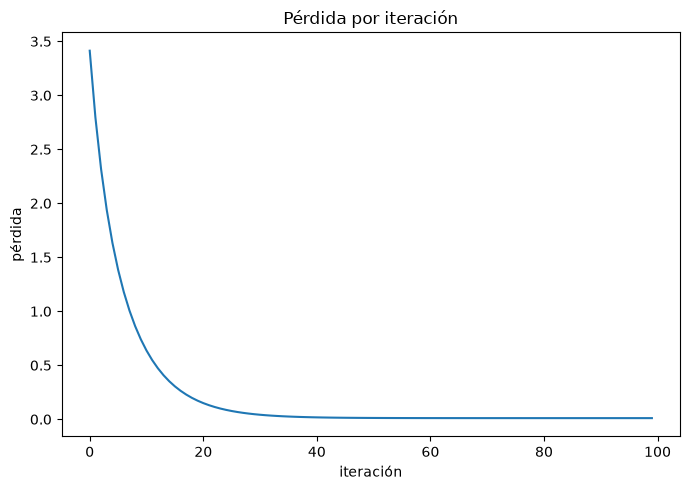

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(loss_history)
ax.set_title('Pérdida por iteración')
ax.set_xlabel('iteración')
ax.set_ylabel('pérdida')

plt.tight_layout()
plt.show()

La pérdida baja rápido al principio y luego se aplana: eso es normal, cerca del mínimo el gradiente es pequeño y los pasos también.

### Comprobación: ¿llegamos a la solución exacta?

La regresión lineal tiene una solución cerrada (mínimos cuadrados), que NumPy calcula con `np.polyfit`. Si el descenso por gradiente funcionó, sus parámetros deben ser casi iguales:

In [8]:
w_exact, b_exact = np.polyfit(x, y, 1)   # ajuste de grado 1: y = w*x + b
print(f'Descenso por gradiente -> w: {w:.3f}  b: {b:.3f}')
print(f'Solución exacta        -> w: {w_exact:.3f}  b: {b_exact:.3f}')

Descenso por gradiente -> w: 1.986  b: 0.992
Solución exacta        -> w: 1.987  b: 0.992


### ¿Cuándo detener el entrenamiento?

Hasta ahora usamos un número fijo de iteraciones, pero hay otras formas de decidir cuándo parar (el *criterio de parada*). Tres habituales:

1. **Máximo de iteraciones o épocas:** se fija de antemano cuántas hacer.
2. **Gradiente casi cero:** cerca del mínimo el gradiente es muy pequeño; se para cuando su tamaño baja de un umbral $\varepsilon$.
3. **Pérdida estable:** se vigila la pérdida y se para cuando deja de bajar de forma apreciable.

Probamos los tres con la misma función, partiendo de $w = 0$, $b = 0$:

In [9]:
def train_until_stop(max_iterations, grad_threshold=None, loss_tolerance=None, lr=0.1):
    w_s, b_s = 0.0, 0.0
    previous_loss = np.inf
    for iteration in range(1, max_iterations + 1):
        y_hat = predict(x, w_s, b_s)
        loss = compute_loss(y_hat, y)
        dw, db = compute_gradients(x, y, y_hat)

        if grad_threshold is not None and np.sqrt(dw**2 + db**2) < grad_threshold:
            return iteration, 'gradiente casi cero', w_s, b_s
        if loss_tolerance is not None and abs(previous_loss - loss) < loss_tolerance:
            return iteration, 'pérdida estable', w_s, b_s

        w_s = w_s - lr * dw
        b_s = b_s - lr * db
        previous_loss = loss
    return max_iterations, 'máximo de iteraciones', w_s, b_s

for name, kwargs in [('solo máximo (30)', dict(max_iterations=30)),
                     ('gradiente < 1e-3', dict(max_iterations=5000, grad_threshold=1e-3)),
                     ('cambio de pérdida < 1e-7', dict(max_iterations=5000, loss_tolerance=1e-7))]:
    iterations, reason, w_s, b_s = train_until_stop(**kwargs)
    print(f'{name:26s} -> paró en la iteración {iterations:4d} ({reason})  w: {w_s:.3f}  b: {b_s:.3f}')

solo máximo (30)           -> paró en la iteración   30 (máximo de iteraciones)  w: 1.792  b: 1.015
gradiente < 1e-3           -> paró en la iteración   98 (gradiente casi cero)  w: 1.986  b: 0.992
cambio de pérdida < 1e-7   -> paró en la iteración   99 (pérdida estable)  w: 1.986  b: 0.992


Los criterios 2 y 3 paran cuando ya casi no se mejora, y el máximo de iteraciones es la red de seguridad por si nunca se cumplen.

**¿Puede quedarse atascado?** En la regresión lineal, la pérdida tiene forma de tazón (es **convexa**) y un único mínimo, así que el descenso por gradiente siempre llega a él. En modelos más complejos, como las redes neuronales, la superficie puede tener varios mínimos locales y zonas planas, y el resultado depende del punto de partida.

## Etapa 7: Época, batch y minibatch

Cuando el conjunto de datos es grande, no conviene calcular la derivada con todos los datos en cada iteración. Por eso los datos se dividen en partes:

- **Batch**: un grupo de datos que se procesa junto. Su tamaño es `batch_size`. Si `batch_size` es igual al número total de datos ($N$), se usan todos los datos en cada iteración.
- **Minibatch**: un batch pequeño, mucho menor que $N$. Cada minibatch produce **un step**, es decir, **una** actualización de los parámetros.
- **Época** (*epoch*): una pasada completa por todos los datos. Con 200 datos y minibatches de 20, una época son $200 / 20 = 10$ iteraciones.
- **SGD** (descenso por gradiente estocástico): descenso por gradiente que usa minibatches. En cada época los datos se **mezclan** (permutación al azar) para que los minibatches cambien. Con `batch_size=1` se llama SGD puro.

Usamos los mismos pasos que antes: un bucle de **steps** (uno por minibatch) dentro de un bucle externo por épocas:

In [10]:
rng = np.random.default_rng(0)
w, b = rng.normal(), rng.normal()          # parámetros iniciales

batch_size = 20
epochs = 20
lr = 0.1
n_updates = 0

for epoch in range(epochs):                          # bucle de épocas
    perm = rng.permutation(N)                        # mezclar los datos
    epoch_loss = 0.0
    for start in range(0, N, batch_size):            # bucle de steps: un step por minibatch
        idx = perm[start:start + batch_size]
        xb, yb = x[idx], y[idx]

        y_hat_batch = predict(xb, w, b)                     # 1. forward con el minibatch
        loss_batch = compute_loss(y_hat_batch, yb)          # 2. pérdida del minibatch
        dw, db = compute_gradients(xb, yb, y_hat_batch)     # 3. derivadas del minibatch
        w = w - lr * dw                                     # 4. actualizar parámetros
        b = b - lr * db

        n_updates += 1
        epoch_loss += loss_batch * len(yb)
    avg_loss = epoch_loss / N                        # pérdida promedio de la época

    if (epoch + 1) % 5 == 0:
        print(f'Época {epoch+1:2d} - pérdida: {avg_loss:.4f}  w: {w:.3f}  b: {b:.3f}')

print(f'\nActualizaciones totales: {n_updates}  (10 por época x {epochs} épocas)')
print(f'Valores reales -> w: {w_real}  b: {b_real}')

Época  5 - pérdida: 0.0120  w: 1.948  b: 0.999
Época 10 - pérdida: 0.0105  w: 1.986  b: 0.991
Época 15 - pérdida: 0.0105  w: 1.987  b: 0.987
Época 20 - pérdida: 0.0105  w: 1.986  b: 0.997

Actualizaciones totales: 200  (10 por época x 20 épocas)
Valores reales -> w: 2.0  b: 1.0


En cada época el modelo hizo 10 actualizaciones y no una. Por eso, con el mismo número de épocas, los minibatches avanzan más rápido.

### Gradiente exacto contra gradiente de un minibatch

El gradiente de un minibatch es una **estimación** del gradiente con todos los datos. Comprobémoslo en un punto fijo ($w = 0$, $b = 0$): para cada tamaño $m$ sacamos 1000 minibatches al azar y miramos el valor medio y la dispersión de $\partial L / \partial w$.

In [11]:
w_test, b_test = 0.0, 0.0
dw_exact, _ = compute_gradients(x, y, predict(x, w_test, b_test))
print(f'Gradiente exacto (200 datos): {dw_exact:.3f}\n')

rng_grad = np.random.default_rng(0)
for m in [1, 5, 20, 100, 200]:
    estimates = []
    for _ in range(1000):
        idx = rng_grad.choice(N, size=m, replace=False)
        dw_est, _ = compute_gradients(x[idx], y[idx], predict(x[idx], w_test, b_test))
        estimates.append(dw_est)
    print(f'm={m:>3}  media de las estimaciones: {np.mean(estimates):6.3f}   dispersión (desv. estándar): {np.std(estimates):.3f}')

Gradiente exacto (200 datos): -1.626

m=  1  media de las estimaciones: -1.601   dispersión (desv. estándar): 1.843
m=  5  media de las estimaciones: -1.592   dispersión (desv. estándar): 0.804
m= 20  media de las estimaciones: -1.618   dispersión (desv. estándar): 0.382
m=100  media de las estimaciones: -1.625   dispersión (desv. estándar): 0.131
m=200  media de las estimaciones: -1.626   dispersión (desv. estándar): 0.000


La media de las estimaciones coincide con el gradiente exacto: en promedio, el minibatch apunta en la dirección correcta. La diferencia está en la **dispersión**: cuanto más pequeño es $m$, más ruidosa es cada estimación. Con $m = N$ no hay ruido. Ese es el equilibrio entre costo por step y estabilidad que vemos a continuación.

## Etapa 8: Comparación de tamaños de batch

Para repetir el ciclo con distintos tamaños, lo guardamos en la función `train`. Entrenamos el mismo modelo, con la misma semilla y el mismo número de épocas, usando tres tamaños de batch. Ojo: se compara a igual número de **épocas**, no de actualizaciones, y cada tamaño hace un número distinto de ellas:

| `batch_size` | Nombre | Iteraciones por época |
|---|---|---|
| 200 | Descenso por gradiente (todos los datos) | 1 |
| 20 | Minibatches | 10 |
| 1 | SGD puro | 200 |

In [12]:
def train(x, y, batch_size, epochs=20, lr=0.1, seed=0):
    n = len(y)
    rng = np.random.default_rng(seed)          # misma inicialización para todos
    w, b = rng.normal(), rng.normal()

    history, n_updates = [], 0
    w_path, b_path = [w], [b]
    for epoch in range(epochs):
        perm = rng.permutation(n)
        epoch_loss = 0.0
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            xb, yb = x[idx], y[idx]
            y_hat_batch = predict(xb, w, b)
            loss_batch = compute_loss(y_hat_batch, yb)
            dw, db = compute_gradients(xb, yb, y_hat_batch)
            w = w - lr * dw
            b = b - lr * db
            n_updates += 1
            epoch_loss += loss_batch * len(yb)
            w_path.append(w)
            b_path.append(b)
        history.append(epoch_loss / n)

    return {'loss': history, 'updates': n_updates, 'w': w, 'b': b, 'w_path': w_path, 'b_path': b_path}

names = {200: 'todos los datos', 20: 'minibatches', 1: 'SGD puro'}
results = {}
for bs in [200, 20, 1]:
    result = train(x, y, bs)
    results[bs] = result
    print(f"batch_size={bs:>3} ({names[bs]:<16}) actualizaciones={result['updates']:>5}  "
          f"w={result['w']:.3f}  b={result['b']:.3f}  pérdida final={result['loss'][-1]:.4f}")

batch_size=200 (todos los datos ) actualizaciones=   20  w=1.604  b=1.025  pérdida final=0.0724
batch_size= 20 (minibatches     ) actualizaciones=  200  w=1.986  b=0.997  pérdida final=0.0105


batch_size=  1 (SGD puro        ) actualizaciones= 4000  w=2.007  b=0.998  pérdida final=0.0119


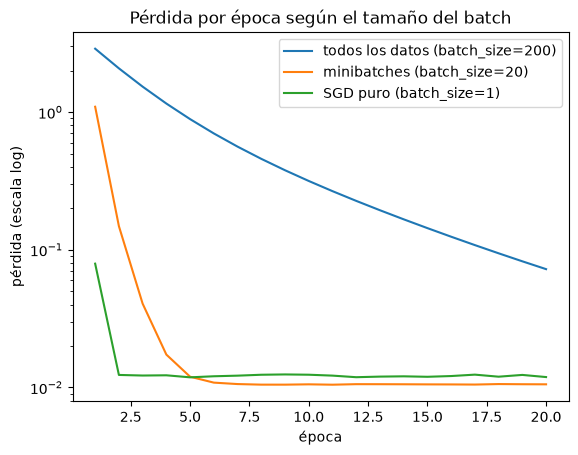

In [13]:
for bs, result in results.items():
    plt.plot(range(1, 21), result['loss'], label=f'{names[bs]} (batch_size={bs})')
plt.yscale('log')
plt.title('Pérdida por época según el tamaño del batch')
plt.xlabel('época')
plt.ylabel('pérdida (escala log)')
plt.legend()
plt.show()

<p align="center">
  <img src="imagenes/04_comparacion_batch_size.png" alt="Comparación de batch_size 200, 20 y 1" width="1200">
</p>

La figura muestra el camino que recorre cada entrenamiento sobre la misma superficie de pérdida de la Etapa 3. Los tres parten del mismo punto (círculo blanco) y dan 20 épocas. Ese punto es distinto al de la Etapa 3, porque en esta etapa reiniciamos el generador de números aleatorios con la semilla 0. Los títulos indican cuántas actualizaciones hizo cada uno:

- **Todos los datos** (20 actualizaciones): el camino es una curva suave, porque cada paso usa el gradiente exacto. Pero termina en $w \approx 1.60$, sin llegar a la estrella. No es que cada paso sea peor, sino que dio muy pocos.
- **Minibatches** (200 actualizaciones): el camino tiene pequeños zigzags, porque cada gradiente es una aproximación ruidosa calculada con solo 20 datos. Aun así llega prácticamente al mismo lugar que la estrella.
- **SGD puro** (4000 actualizaciones): el camino es el más irregular, porque cada paso usa un solo dato. Alrededor de la estrella se queda dando vueltas en lugar de detenerse.

## Extra: más de una variable de entrada

Hasta ahora cada muestra tenía una sola entrada $x$. En la práctica hay $n$ entradas, y el modelo pasa a ser

$$
\hat{y} = w_1 x_1 + w_2 x_2 + \cdots + w_n x_n + b
$$

Ahora hay $n + 1$ parámetros: un peso por entrada y el sesgo. **Todo lo demás es igual**: la pérdida MSE, el gradiente (una derivada por parámetro) y la regla de actualización. Solo cambia que los cálculos se escriben con matrices:

- `X` tiene forma `(N, n)`: una fila por muestra, una columna por entrada.
- `w` es un vector de `n` pesos, y la predicción de todas las muestras es `X @ w + b`.
- El gradiente respecto a `w` es `(2/N) * X.T @ (y_hat - y)`.

Probamos con $n = 3$ entradas:

In [14]:
rng_multi = np.random.default_rng(1)
n_features = 3
w_true, b_true = np.array([2.0, -1.0, 0.5]), 1.0

X = rng_multi.uniform(-1, 1, size=(N, n_features))                    # (200, 3)
y_multi = X @ w_true + b_true + 0.1 * rng_multi.normal(size=N)

def predict_multi(X, w, b):
    return X @ w + b                                  # (N, n) @ (n,) -> (N,)

def gradients_multi(X, y, y_hat):
    n = len(y)
    dw = (2 / n) * X.T @ (y_hat - y)                  # un gradiente por cada peso
    db = (2 / n) * np.sum(y_hat - y)
    return dw, db

w_multi, b_multi = np.zeros(n_features), 0.0
for iteration in range(500):
    y_hat = predict_multi(X, w_multi, b_multi)
    dw, db = gradients_multi(X, y_multi, y_hat)
    w_multi = w_multi - 0.1 * dw
    b_multi = b_multi - 0.1 * db

print('Pesos reales:   ', w_true, ' sesgo:', b_true)
print('Pesos aprendidos:', np.round(w_multi, 3), ' sesgo:', round(b_multi, 3))

Pesos reales:    [ 2.  -1.   0.5]  sesgo: 1.0
Pesos aprendidos: [ 2.002 -0.985  0.501]  sesgo: 0.983


Con varias entradas, el modelo sigue siendo lineal: guarda una matriz de pesos y un sesgo, y calcula `X @ W.T + b`. Es la misma idea con más entradas (y, más adelante, con más salidas a la vez).



## Resumen

| Concepto | Qué es | Dónde aparece en el código |
|---|---|---|
| Modelo | Función con parámetros que se ajustan | `predict(x, w, b)` |
| Forward | Calcular la predicción | `y_hat = predict(x, w, b)` |
| Pérdida | Medida del error del modelo | `compute_loss(y_hat, y)` |
| Gradiente | Derivadas de la pérdida respecto a cada parámetro (aquí, a mano) | `compute_gradients(x, y, y_hat)` |
| Step | Actualizar parámetros | `w = w - lr * dw` |
| Tasa de aprendizaje | Tamaño del paso de actualización | `lr = 0.1` |
| Iteración | Un ciclo de los pasos | una vuelta del bucle |
| Batch / minibatch | Grupo de datos usado en una iteración | `batch_size`, `x[idx], y[idx]` |
| Época | Una pasada por todos los datos | un bucle `for epoch in range(epochs)` |

Estos mismos pasos (modelo, pérdida, gradiente, actualización de parámetros) son los que repetiremos al entrenar redes neuronales.

## Ejercicios

1. Con `batch_size=20`, cambia `lr` a `0.01` y luego a `0.5` en la llamada a `train`. ¿Cuál converge más lento? ¿Cuál oscila?
2. Si hay 200 datos y el batch es de 32, ¿cuántas iteraciones hay por época? (Pista: el último batch tiene menos de 32 datos.)
3. Cambia `dw` en `compute_gradients` para que esté mal (por ejemplo, quita el factor `2 / n`). Vuelve a correr la comprobación numérica: ¿cómo detectas el error?
4. Cambia `N` a 2000 y vuelve a ejecutar el notebook desde el inicio. Compara el número de actualizaciones y el tiempo de entrenamiento entre `batch_size=200` y `batch_size=1`. Ojo: con `N=2000`, `batch_size=200` ya no usa todos los datos, sino un minibatch.
5. Prueba `lr=1.1` con `batch_size=200`. ¿Qué pasa? Compáralo con el límite de $\eta \approx 1$ que mencionamos en la Etapa 5.